### 1.DATA READING

In [1]:
#import library
import numpy as np
import pandas as pd

In [2]:
adv=pd.read_csv(r"D:\Datasets\advertising (1).csv")
adv

,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,12.0
3,151.5,41.3,58.5,16.5
4,180.8,10.8,58.4,17.9
...,...,...,...,...
195,38.2,3.7,13.8,7.6
196,94.2,4.9,8.1,14.0
197,177.0,9.3,6.4,14.8
198,283.6,42.0,66.2,25.5


In [3]:
adv.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   Radio      200 non-null    float64
 2   Newspaper  200 non-null    float64
 3   Sales      200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB


In [4]:
adv.shape

(200, 4)

### 2.DATA CLEANING

In [5]:
adv.isnull().sum()

TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64

In [6]:
adv.dtypes

TV           float64
Radio        float64
Newspaper    float64
Sales        float64
dtype: object

In [7]:
for i in adv.columns:
    print(i,':',"\n",adv[i].unique())

TV : 
 [230.1  44.5  17.2 151.5 180.8   8.7  57.5 120.2   8.6 199.8  66.1 214.7
  23.8  97.5 204.1 195.4  67.8 281.4  69.2 147.3 218.4 237.4  13.2 228.3
  62.3 262.9 142.9 240.1 248.8  70.6 292.9 112.9  97.2 265.6  95.7 290.7
 266.9  74.7  43.1 228.  202.5 177.  293.6 206.9  25.1 175.1  89.7 239.9
 227.2  66.9 100.4 216.4 182.6 262.7 198.9   7.3 136.2 210.8 210.7  53.5
 261.3 239.3 102.7 131.1  69.   31.5 139.3 216.8 199.1 109.8  26.8 129.4
 213.4  16.9  27.5 120.5   5.4 116.   76.4 239.8  75.3  68.4 213.5 193.2
  76.3 110.7  88.3 134.3  28.6 217.7 250.9 107.4 163.3 197.6 184.9 289.7
 135.2 222.4 296.4 280.2 187.9 238.2 137.9  25.   90.4  13.1 255.4 225.8
 241.7 175.7 209.6  78.2  75.1 139.2 125.7  19.4 141.3  18.8 224.  123.1
 229.5  87.2   7.8  80.2 220.3  59.6   0.7 265.2   8.4 219.8  36.9  48.3
  25.6 273.7  43.   73.4 193.7 220.5 104.6  96.2 140.3 243.2  38.   44.7
 280.7 121.  171.3 187.8   4.1  93.9 149.8  11.7 131.7 172.5  85.7 188.4
 163.5 117.2 234.5  17.9 206.8 215.4 284.3  

In [8]:
d=adv.describe(include='all')
d

,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,15.130500
std,85.854236,14.846809,21.778621,5.283892
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,11.000000
50%,149.750000,22.900000,25.750000,16.000000
75%,218.825000,36.525000,45.100000,19.050000
max,296.400000,49.600000,114.000000,27.000000


### 3.DATA ANALYSIS

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

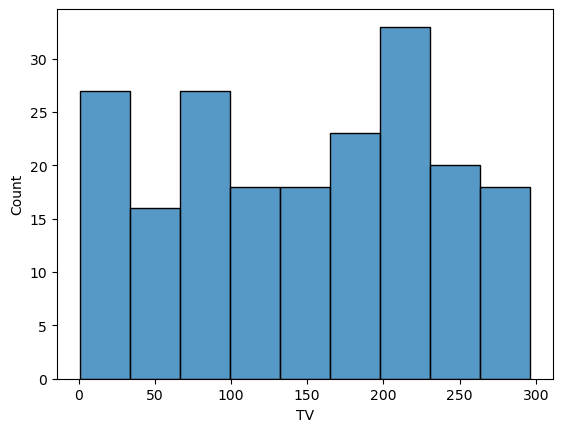

In [10]:
sns.histplot(adv['TV'])
plt.show()

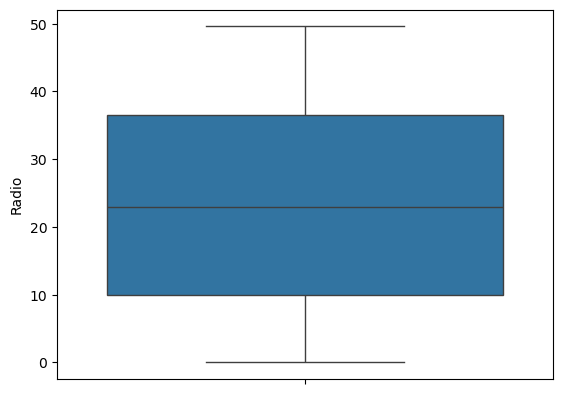

In [11]:
sns.boxplot(adv.Radio)
plt.show()

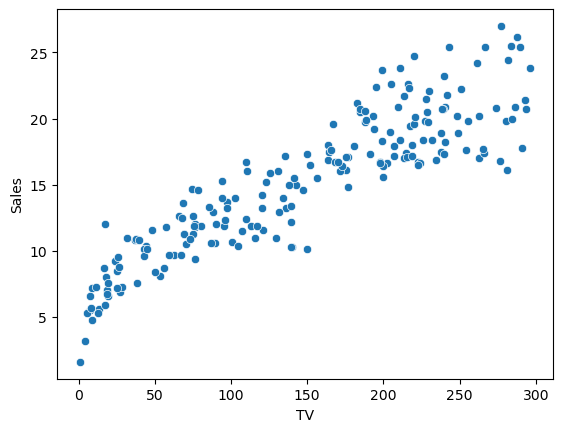

In [12]:
sns.scatterplot(x='TV', y='Sales', data=adv)
plt.show()

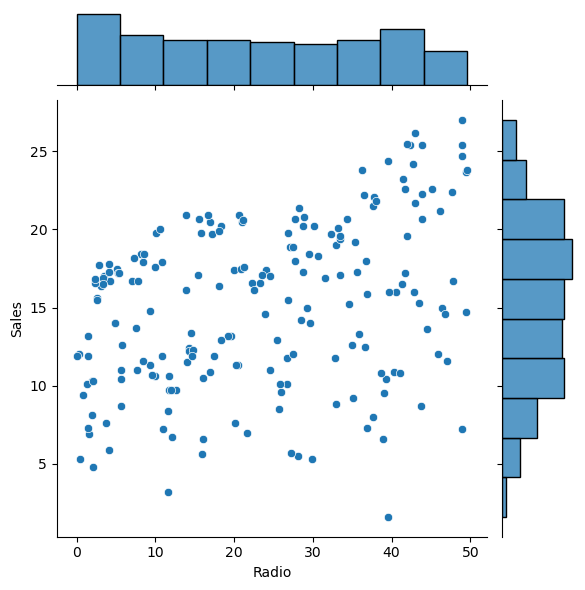

In [13]:
sns.jointplot(x='Radio', y='Sales', data=adv)
plt.show()

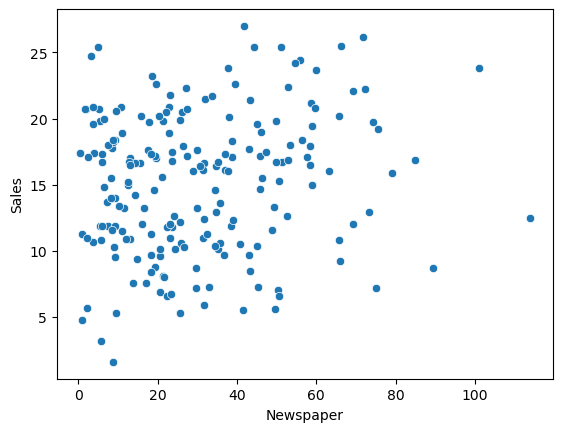

In [14]:
sns.scatterplot(x='Newspaper', y='Sales', data=adv)
plt.show()

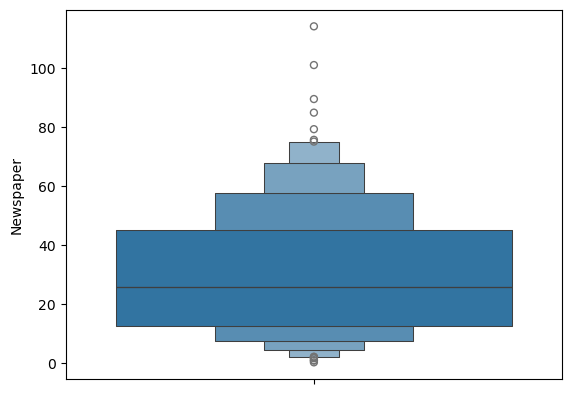

In [15]:
sns.boxenplot(adv.Newspaper)
plt.show()

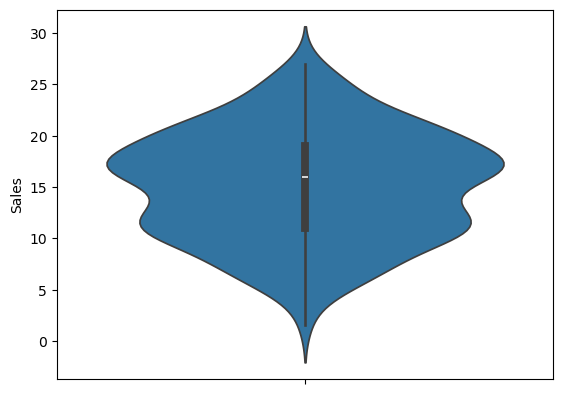

In [16]:
sns.violinplot(adv.Sales)
plt.show()

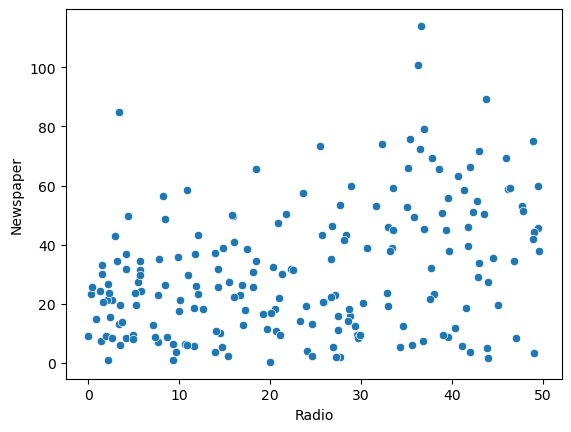

In [17]:
sns.scatterplot(x='Radio', y='Newspaper', data=adv)
plt.show()

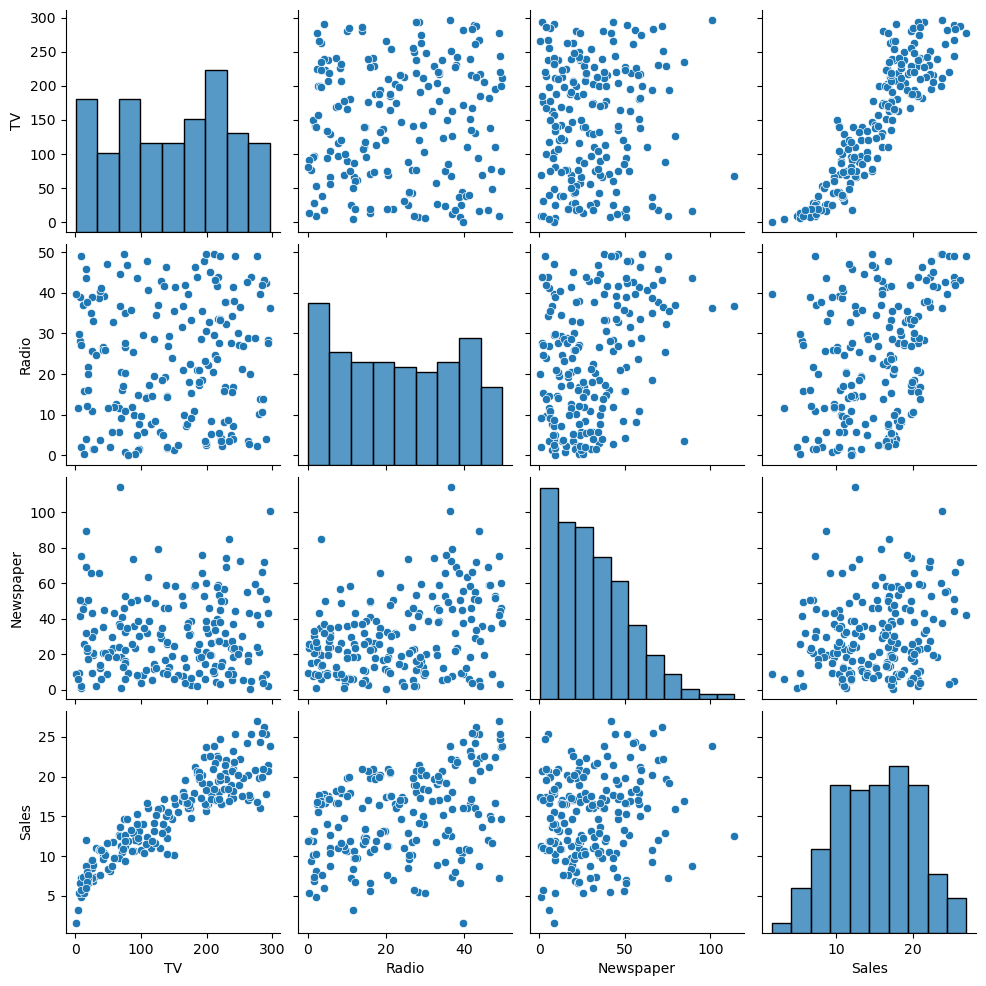

In [18]:
sns.pairplot(adv)
plt.show()

### 4.ENCODING

In [19]:
#no need of encoding because here we have all columns as numeric

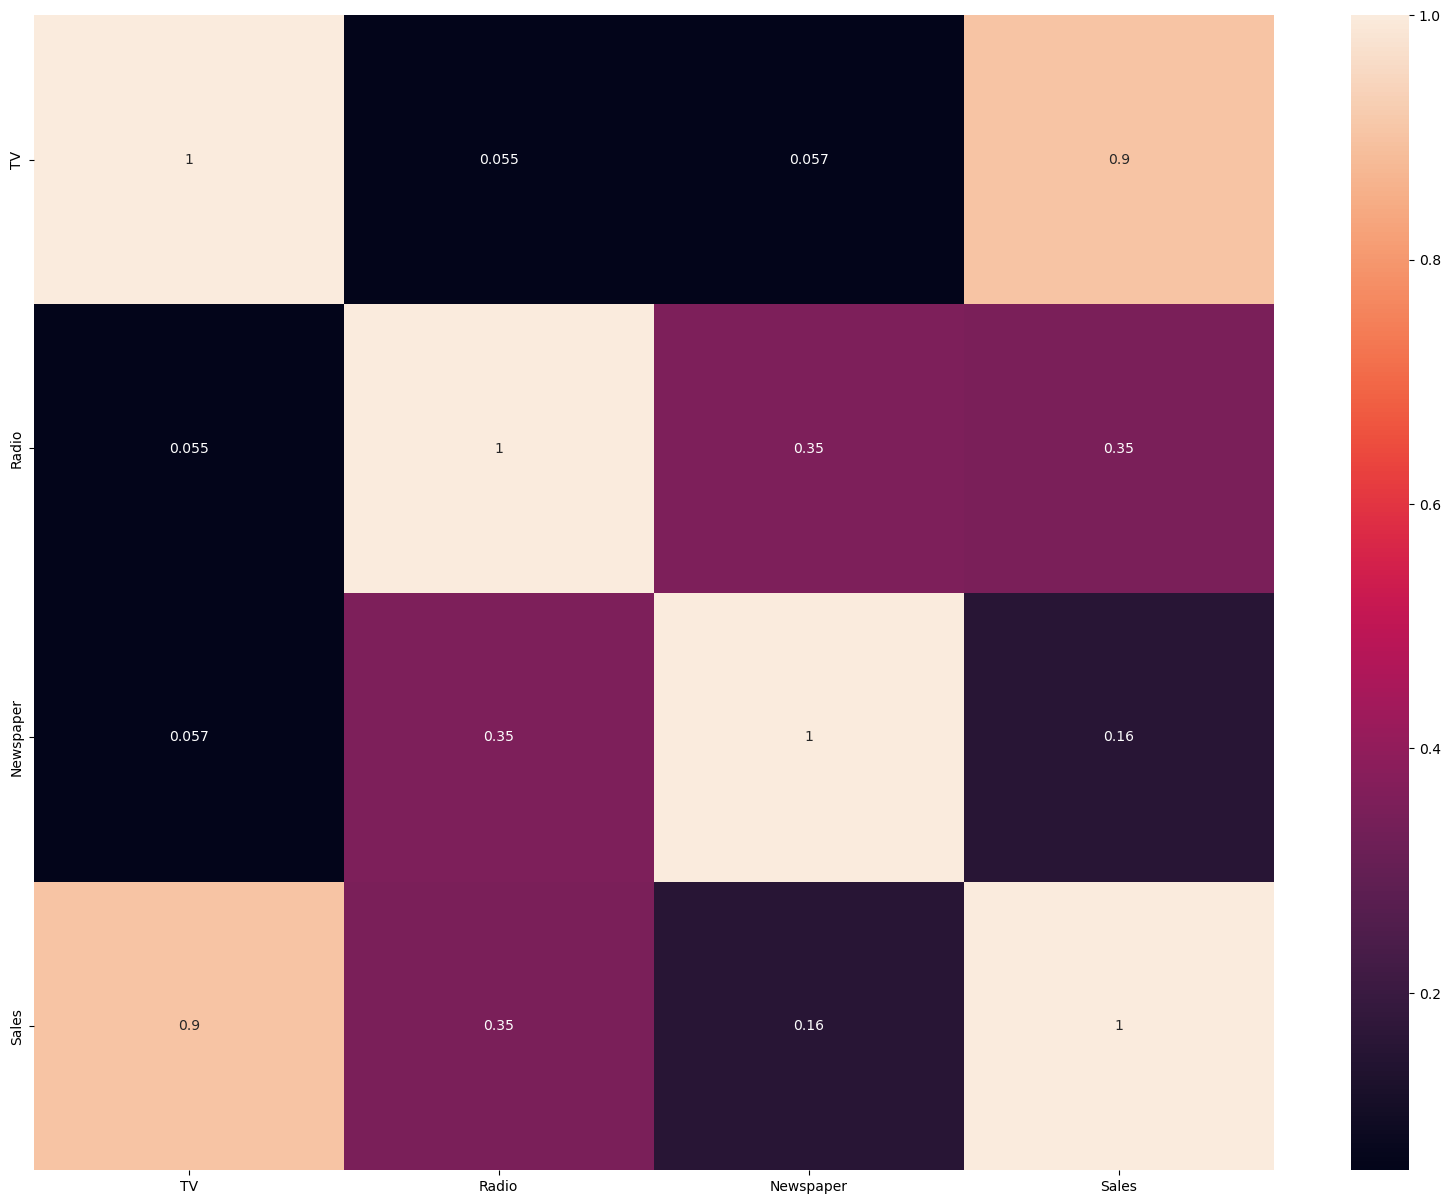

In [10]:
#Heat map:it used to show the co-relationship
#between numeric columns.
c=adv.corr()
plt.figure(figsize=(20,15))
sns.heatmap(c,annot=True)
plt.show()

### 5.Input/Output Creation

In [11]:
ip=adv.drop('Sales',axis=1)
ip

,TV,Radio,Newspaper
0,230.1,37.8,69.2
1,44.5,39.3,45.1
2,17.2,45.9,69.3
3,151.5,41.3,58.5
4,180.8,10.8,58.4
...,...,...,...
195,38.2,3.7,13.8
196,94.2,4.9,8.1
197,177.0,9.3,6.4
198,283.6,42.0,66.2


In [12]:
op=adv.Sales
op

0      22.1
1      10.4
2      12.0
3      16.5
4      17.9
       ... 
195     7.6
196    14.0
197    14.8
198    25.5
199    18.4
Name: Sales, Length: 200, dtype: float64

### 6.Train Test Split

In [13]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(ip,op,train_size=0.8)

In [14]:
print(x_train.shape)
print(x_test.shape)

(160, 3)
(40, 3)


### 7.Standard Scaler

In [15]:
from sklearn.preprocessing import StandardScaler
sc=StandardScaler()
x_train=sc.fit_transform(x_train)
x_test=sc.transform(x_test)

In [16]:
x_train

array([[-1.19851575e+00,  2.16629232e-01, -4.95785838e-01],
       [-1.19733038e+00,  2.72053062e-01,  1.75025467e-01],
       [ 6.49480646e-01,  1.84470422e+00,  1.31908036e+00],
       [-1.27082350e+00,  1.09648252e+00,  1.57637785e+00],
       [ 6.60149002e-01, -1.36294990e+00,  1.52052477e-01],
       [ 3.36542192e-01, -3.23753102e-01, -2.71368443e-02],
       [-6.61541815e-01,  1.88917318e-01,  1.93475649e+00],
       [-3.96018279e-01,  1.23504209e+00,  1.46610750e+00],
       [-8.71352824e-01, -4.69240654e-01,  4.36917551e-01],
       [-2.73924867e-01, -9.95767032e-01,  7.99890792e-01],
       [-5.67897354e-01, -5.52376398e-01,  3.49620190e-01],
       [-8.18011042e-01,  8.47075290e-01,  9.83674711e-01],
       [-8.90318791e-01, -9.33415224e-01, -1.39632704e+00],
       [-9.24694606e-01, -1.17589448e+00, -3.25785713e-01],
       [ 1.61911570e+00, -6.14728206e-01,  2.62322828e-01],
       [-1.40477064e+00,  1.12419444e+00, -1.01038081e+00],
       [-1.11553965e+00, -7.74071715e-01

In [17]:
x_test

array([[ 0.83676957,  0.08499764, -1.2538945 ],
       [-0.75755702, -1.57771724, -1.01497541],
       [-0.33319351, -1.04426288, -0.37632629],
       [ 1.30025038, -0.10205779, -0.05929903],
       [ 1.68194047, -0.61472821, -1.2676783 ],
       [-0.40668664,  1.73385656,  0.92394494],
       [-0.82275253,  1.84470422,  0.66205285],
       [-1.2577844 ,  1.21425816, -0.89092126],
       [ 0.22748788,  0.61152402,  0.99286391],
       [-0.80260119, -1.52229341, -0.75767792],
       [ 1.45553424,  1.45673741, -1.20794852],
       [ 1.31921635,  0.28590902, -1.18497553],
       [-1.04204653, -1.18282246, -0.07308282],
       [ 1.04302446, -0.98191107, -1.0379484 ],
       [-1.13569099,  1.67843273, -1.0471376 ],
       [ 1.13785429, -0.4207448 , -0.38551549],
       [ 1.77202881,  0.34133285, -1.35497566],
       [ 0.6340708 , -1.33523799, -1.16659714],
       [ 0.25475146, -0.88491937, -0.62902918],
       [-1.60509867,  1.81006432,  2.00827006],
       [-1.18073516,  1.14497837,  0.634

### 8.Machine Learning Model

In [18]:
from sklearn.linear_model import LinearRegression
lr=LinearRegression()
lr.fit(x_train,y_train)

LinearRegression()

In [19]:
lr.intercept_

np.float64(14.984375)

In [20]:
lr.coef_

array([ 4.6588601 ,  1.60707709, -0.06290242])

### 9.Prediction

In [21]:
pred=lr.predict(x_test)
pred

array([19.09823811,  8.98335401, 11.77753392, 20.88177496, 21.91212476,
       15.81800163, 14.0742232 , 11.13198102, 16.96452191,  8.84638524,
       24.18257759, 21.66443509,  8.23333624, 18.33096271, 12.45658784,
       19.63355949, 23.87378877, 15.86597355, 14.78866022, 10.28903271,
       11.28365293, 16.52430032, 14.19224847,  9.69331462, 20.16266707,
       17.96255051,  6.93680089, 19.47437981, 21.06126408, 15.59923193,
       21.0666971 , 14.01040081, 20.63678522, 25.14117437, 10.44090385,
       21.53904629,  7.6962666 , 18.04647717, 12.51448862, 20.3448767 ])

In [22]:
from sklearn.metrics import r2_score,mean_squared_error
r2=r2_score(y_test,pred)
mse=mean_squared_error(y_test,pred)
print('Accuracy:',r2)
print("Mean squared error:",mse)

Accuracy: 0.8987630406117981
Mean squared error: 2.460794612012855


In [23]:
df=pd.DataFrame({'Y_test':list(y_test),
                 'Prediction':pred})
df

,Y_test,Prediction
0,17.4,19.098238
1,11.9,8.983354
2,11.0,11.777534
3,17.6,20.881775
4,20.9,21.912125
5,16.7,15.818002
6,14.7,14.074223
7,10.9,11.131981
8,16.9,16.964522
9,9.4,8.846385


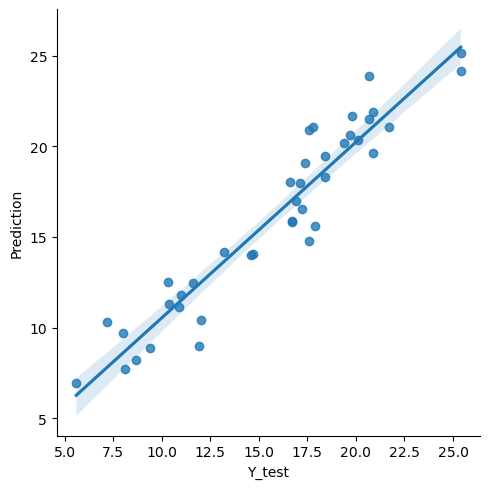

In [24]:
#lmplot-Linear model plot
sns.lmplot(x='Y_test',y='Prediction',
          data=df)
plt.show()